# Каталог фитов: что переживает кат по SN-хитам и как при этом выглядит скор

Каталог `inference/track_fit_alike_bars/sample/fits.duckdb` — это реконструкция
а-ля BARS, прогнанная по **естественной** выборке: непрерывные окна партов h5,
без отбора по скору, из которых выброшено только то, на чём учился чекпоинт.
44 млн событий, по строке на событие, ключ — `event_fk`.

Два свойства каталога определяют всё, что ниже, и оба легко перепутать:

* **выборка естественная.** Проскоренные события попадают в неё своим
  естественным темпом (для данных — примерно каждое двадцатое). Поэтому событие
  без скора — это не пропущенная строка, а событие, не прошедшее кат, который
  скоринг применяет до записи: для `exp_full` это `--min-hits 5` при
  `--min-strings 0`, то есть **наличие в базе предсказаний и есть кат «≥5 хитов
  SN»**. Его `n_sn_hits` не неизвестен — он ниже порога.
* **значения есть только у `status`.** Все переменные фита `NULL`, пока фит не
  сошёлся, а `status` говорит, почему не сошёлся (`no_clique`,
  `no_offline_trigger`, ...). Фильтр по переменной молча выбрасывает несшедшиеся.

Здесь не читается ни один хит: скоры и число SN-хитов берутся из базы
предсказаний, треки — из каталога фитов.

In [1]:
import os, sys
os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")

ROOT = "/home/albert/Baikal2025"
sys.path.insert(0, ROOT)

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from inference import reader

pd.set_option("display.width", 200)

CHECKPOINT = ("260816_2250_da_nu_classifier_exp_full_E1_lambda0.01_FIXED_sn256"
              "@best_da_model")
# Базы предсказаний: единственное место, откуда берутся скоры и число SN-хитов.
PRED_DIR = f"{ROOT}/inference/nu_classifier/preds/{CHECKPOINT}"
PRED_TABLES = {"exp_full": "exp_full", "mc_merged": "mc_merged"}

ORDER = ["exp_full", "muatm_2020", "nuatm_2020", "nue2_2020"]

catalogue = reader.open_fits()
print(repr(catalogue), "| колонок:", len(catalogue.columns()))

<Fits fits.duckdb> | колонок: 51


In [2]:
# Одно соединение: каталог фитов + манифест (домены) + базы предсказаний (скоры)
# + каталог событий. Каталог нужен ровно для одного: узнать, какие части файла
# вообще покрыты вероятностями SN-модели (см. воронку ниже).
con = catalogue.connection()
for source, table in PRED_TABLES.items():
    con.execute(f"ATTACH '{PRED_DIR}/{table}_thr0p8.duckdb' AS pred_{source} (READ_ONLY)")
con.execute(f"ATTACH '{ROOT}/data_manager/catalog_v2.duckdb' AS cat (READ_ONLY)")

con.execute(f"""
    CREATE VIEW events AS
    SELECT f.*, m.data_class, p.score, p.n_sn_hits, p.n_sn_strings
    FROM fitness.fits f
    JOIN {catalogue.manifest_sql()} m USING (event_fk)
    LEFT JOIN (SELECT * FROM pred_exp_full.predictions
               UNION ALL SELECT * FROM pred_mc_merged.predictions) p USING (event_fk)
""")

# Части, покрытые вероятностями SN-модели: `(data_class, part_key)`, потому что
# `part_key` один на три класса. Только из них событие и может быть проскорено --
# без вероятностей классификатору нечего подавать на вход. Для exp_full и для
# nuatm/nue2 покрыто всё, для muatm -- половина частей (10 100 из 20 004).
con.execute(f"""
    CREATE VIEW scoreable AS
    SELECT DISTINCT e.data_class, l.part_key
    FROM pred_exp_full.predictions p
    JOIN cat.events e ON e.id = p.event_fk
    JOIN cat.h5_locations l ON l.event_fk = e.id
    UNION
    SELECT DISTINCT e.data_class, l.part_key
    FROM pred_mc_merged.predictions p
    JOIN cat.events e ON e.id = p.event_fk
    JOIN cat.h5_locations l ON l.event_fk = e.id
""")
print(f"{con.execute('SELECT count(*) FROM events').fetchone()[0]:,} событий в соединении")
print(f"{con.execute('SELECT count(*) FROM scoreable').fetchone()[0]:,} партов, покрытых скорингом")

44,000,880 событий в соединении


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

12,529 партов, покрытых скорингом


## 1. Сколько сошедшихся событий проходит кат «≥5 хитов SN»

Скор есть ровно у тех событий, что прошли кат (см. выше), поэтому
`score IS NOT NULL` и есть ответ на вопрос — считаем и явно, по `n_sn_hits`,
чтобы это было видно, а не следовало из свойств конвейера.

In [3]:
counts = con.execute("""
    SELECT data_class,
           count(*)                                              AS в_выборке,
           count(*) FILTER (status = 'ok')                       AS фит_сошёлся,
           count(*) FILTER (status = 'ok' AND score IS NOT NULL) AS сошёлся_и_кат,
           round(100.0 * count(*) FILTER (status = 'ok') / count(*), 2) AS процент_сошедшихся,
           round(100.0 * count(*) FILTER (status = 'ok' AND score IS NOT NULL)
                 / count(*) FILTER (status = 'ok'), 1)           AS процент_ката_среди_сошедшихся
    FROM events GROUP BY 1 ORDER BY 1
""").df()
counts

,data_class,в_выборке,фит_сошёлся,сошёлся_и_кат,процент_сошедшихся,процент_ката_среди_сошедшихся
0,exp_full,29999920,517749,436855,1.73,84.4
1,muatm_2020,10001600,1616064,749326,16.16,46.4
2,nuatm_2020,1999360,170569,155727,8.53,91.3
3,nue2_2020,2000000,705625,669649,35.28,94.9


Строки читаются так: из выборки такого-то домена фит сошёлся у стольких-то, и из
них столько-то процентов прошли кат по SN-хитам. Проценты намеренно не
сравниваются между доменами «в лоб»: выборки разные по составу, а кат по SN —
это ещё один отбор поверх того, что делает фит.

### Кат h8s3 с обеих сторон

Тот же кат, но поставленный дважды и разными руками: **SN-модель** считает сигнальные
хиты по своим вероятностям (`n_sn_hits`, `n_sn_strings` из базы предсказаний), а
**реконструкция** — по своему отбору (`n_hits`, `n_strings` самого фита, то есть
хиты финального трека). Условие одно и то же — не меньше 8 хитов на не меньше чем
3 стрингах, — но наборы хитов разные, и совпадение тут не гарантировано.

Событий без скора это не касается: у них `n_sn_hits < 5` по построению (кат
скоринга), то есть h8s3 они пройти не могли, и пропуск здесь — не потеря.

In [4]:
h8s3 = con.execute("""
    SELECT data_class,
           count(*) FILTER (status = 'ok' AND n_hits >= 8 AND n_strings >= 3)
               AS прошли_h8s3_реко,
           count(*) FILTER (status = 'ok' AND n_hits >= 8 AND n_strings >= 3
                            AND n_sn_hits >= 8 AND n_sn_strings >= 3)
               AS из_них_прошли_h8s3_sn,
           round(100.0 * count(*) FILTER (
                     status = 'ok' AND n_hits >= 8 AND n_strings >= 3
                     AND n_sn_hits >= 8 AND n_sn_strings >= 3)
                 / nullif(count(*) FILTER (
                     status = 'ok' AND n_hits >= 8 AND n_strings >= 3), 0), 1)
               AS процент_согласия
    FROM events GROUP BY 1 ORDER BY 1
""").df()
h8s3

,data_class,прошли_h8s3_реко,из_них_прошли_h8s3_sn,процент_согласия
0,exp_full,371522,247693,66.7
1,muatm_2020,1066803,310228,29.1
2,nuatm_2020,75712,13904,18.4
3,nue2_2020,523455,336655,64.3


## Воронка отборов

Сколько событий доживает до каждого шага. Шаги считаются **последовательно**:
каждый следующий определён только на том, что прошло предыдущий.

1. **сырых** — всё, на чём вообще применялся фит (естественная выборка);
2. **фит сошёлся** — `status = 'ok'`;
3. **прошли каты качества реконструкции** — рекомендованный набор из
   [doc/reco_quality_cuts.md](../../../../doc/reco_quality_cuts.md);
4. **проскорено** — попало в базу предсказаний (для `exp_full` это «≥5 хитов SN»).

Две оговорки, без которых таблица читается неверно.

**Про каты — что именно применено.** «Стандартный набор» в проекте не один. Взяты
все рекомендованные, **кроме четырёх**:

* `thetaRec < 80` — отбор на нейтринность, а не на качество (по условию задачи);
* `scfMaxTheta < 1.7` — тоже отбор направления, только замаскированный: 1.7 рад это
  97°, чуть за горизонтом. У проходящих его событий медианный `theta_rec` равен
  21–65°, у не проходящих — 148–154°, а проходит его 0.4 % данных и 0.3 % мюонов
  против 99 % атмосферных нейтрино;
* `pathLength > 50` — в порте не считается (вместо него смотрели `z_dist`);
* `nCalls < 350` — число вызовов минимизатора в порте не сравнимо с Minuit2.

Оставшиеся: `nHits ≥ 8`, `nStrings ≥ 2`, `covMatrixStatus == 3`,
`log10(pHit) > −9`, `evCenterZ < 220`, `zDist > 70`,
`log10(funcValue/(nHits−5)) < 1.1`, `nTriplets/nHits > 0.1`, `thetaErr < 2.5`.

**Про скорируемость.** Последний шаг определён не для всех: вероятности SN-модели
покрывают 10 100 из 20 004 частей `mc_merged`, и события из непокрытых частей
проскорены быть не могут в принципе — у классификатора нет входа. Доля таких
событий попадает прямо в знаменатель, поэтому воронка считается **на событиях из
покрытых частей**, а выброшенные показаны отдельной таблицей ниже. Для `exp_full`
и для `nuatm`/`nue2` покрыто всё, для `muatm` — половина.

In [5]:
# Каты качества реконструкции (doc/reco_quality_cuts.md), без четырёх условий,
# объяснённых выше: thetaRec<80 и scfMaxTheta<1.7 -- отборы направления,
# pathLength в порте нет, nCalls не сравним с Minuit2.
QUALITY = """status = 'ok'
    AND n_hits >= 8 AND n_strings >= 2
    AND cov_matrix_status = 3
    AND log_phit_30_min > -9
    AND ev_center_z < 220
    AND z_dist > 70
    AND log10(func_value / nullif(n_hits - 5, 0)) < 1.1
    AND (n_triplets / nullif(n_hits, 0)) > 0.1
    AND theta_err < 2.5"""

funnel = con.execute(f"""
    SELECT data_class,
           count(*)                                          AS сырых,
           count(*) FILTER (status = 'ok')                    AS сошёлся,
           count(*) FILTER ({QUALITY})                        AS прошли_каты,
           count(*) FILTER ({QUALITY} AND score IS NOT NULL)  AS проскорено
    FROM events
    WHERE (data_class, part_key) IN (SELECT data_class, part_key FROM scoreable)
    GROUP BY 1 ORDER BY 1
""").df()
for column in ("сырых", "сошёлся", "прошли_каты", "проскорено"):
    funnel[f"{column}_%"] = (100 * funnel[column] / funnel["сырых"]).round(2)
funnel

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,data_class,сырых,сошёлся,прошли_каты,проскорено,сырых_%,сошёлся_%,прошли_каты_%,проскорено_%
0,exp_full,29999920,517749,104205,96135,100.0,1.73,0.35,0.32
1,muatm_2020,4872208,800006,240345,233677,100.0,16.42,4.93,4.80
2,nuatm_2020,1999360,170569,107321,102706,100.0,8.53,5.37,5.14
3,nue2_2020,2000000,705625,503104,488774,100.0,35.28,25.16,24.44


In [6]:
# Сколько событий выброшено из воронки как непокрытые скорингом.
uncovered = con.execute(f"""
    SELECT data_class,
           count(*)                                        AS событий_вне_покрытия,
           count(*) FILTER (status = 'ok')                  AS из_них_сошлось,
           count(*) FILTER ({QUALITY})                      AS из_них_прошли_каты
    FROM events
    WHERE (data_class, part_key) NOT IN (SELECT data_class, part_key FROM scoreable)
    GROUP BY 1 ORDER BY 1
""").df()
uncovered

# И то же по шагам: сколько остаётся от предыдущего шага.
steps = pd.DataFrame({
    "шаг": ["сырых → сошёлся", "сошёлся → каты", "каты → проскорено"],
    **{row.data_class: [100 * row.сошёлся / row.сырых,
                        100 * row.прошли_каты / row.сошёлся,
                        100 * row.проскорено / row.прошли_каты]
       for row in funnel.itertuples()},
}).set_index("шаг").round(1)
steps

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,exp_full,muatm_2020,nuatm_2020,nue2_2020
шаг,,,,
сырых → сошёлся,1.7,16.4,8.5,35.3
сошёлся → каты,20.1,30.0,62.9,71.3
каты → проскорено,92.3,97.2,95.7,97.2


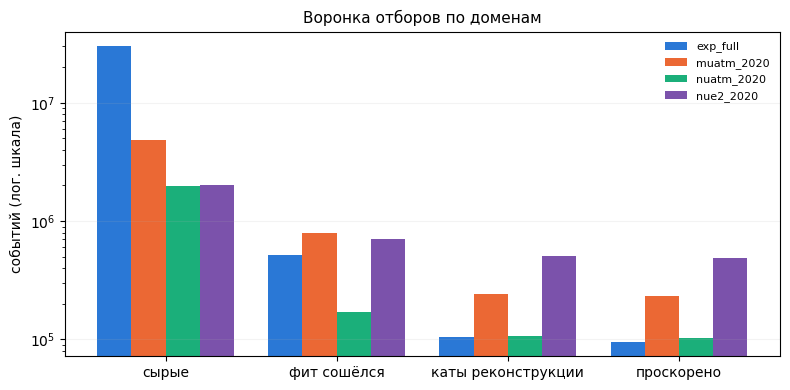

In [7]:
fig, axis = plt.subplots(figsize=(8, 4))
stages = ["сырых", "сошёлся", "прошли_каты", "проскорено"]
width = 0.2
for k, (domain, colour) in enumerate(zip(funnel.data_class,
                                         ("#2a78d6", "#eb6834", "#1baf7a", "#7b52ab"))):
    values = [funnel.loc[funnel.data_class == domain, s].iloc[0] for s in stages]
    axis.bar([i + (k - 1.5) * width for i in range(len(stages))], values,
             width=width, color=colour, label=domain)
axis.set_yscale("log")
axis.set_xticks(range(len(stages)))
axis.set_xticklabels(["сырые", "фит сошёлся", "каты реконструкции", "проскорено"])
axis.set_ylabel("событий (лог. шкала)")
axis.set_title("Воронка отборов по доменам", fontsize=11)
axis.grid(alpha=0.15, axis="y")
axis.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## 2. Распределение скоров

Тут есть тонкость, которую лучше сказать сразу: **среди проскоренных событий кат
«≥5 хитов SN» выполняется по построению** — база предсказаний пишется уже после
этого ката (`--min-hits 5`), и без скора событие на оси скоров просто не
существует. Поэтому «сошёлся и ≥5» — это в точности «сошёлся среди проскоренных»,
а разница между «сошёлся» и «сошёлся и ≥5» — события **без** скора, то есть
ответ первой таблицы (84 % у данных, 46 % у мюонов), а не форма кривой.

Что можно показать на скоре:

* **все проскоренные** события выборки — естественное распределение, с которым
  сравнивать;
* **из них сошедшиеся** — и тогда видно, сдвигает ли фит этот спектр;
* и отдельно — **доля сошедшихся как функция скора**: если фит режет на самом
  скоровом хвосте, это будет видно прямо здесь.

Проскоренных в выборке всего 3.3 млн из 44 — остальные кат не прошли, и это
тоже ответ, а не потеря данных.

In [8]:
# Биннинг в SQL, рисование по маленькой таблице: 4 домена × 2 группы × 50 бинов.
hist = con.execute("""
    SELECT data_class,
           (status = 'ok') AS сошёлся,
           least(49, greatest(0, floor(score * 50)::INT)) AS bin,
           count(*) AS событий
    FROM events
    WHERE score IS NOT NULL
    GROUP BY 1, 2, 3
    ORDER BY 1, 2, 3
""").df()
proskoreno = int(hist.событий.sum())
print(f"{len(hist)} строк гистограммы, проскоренных событий {proskoreno:,}")
hist.head()

387 строк гистограммы, проскоренных событий 3,313,848


,data_class,сошёлся,bin,событий
0,exp_full,False,0,235718
1,exp_full,False,1,15622
2,exp_full,False,2,6988
3,exp_full,False,3,4457
4,exp_full,False,4,3288


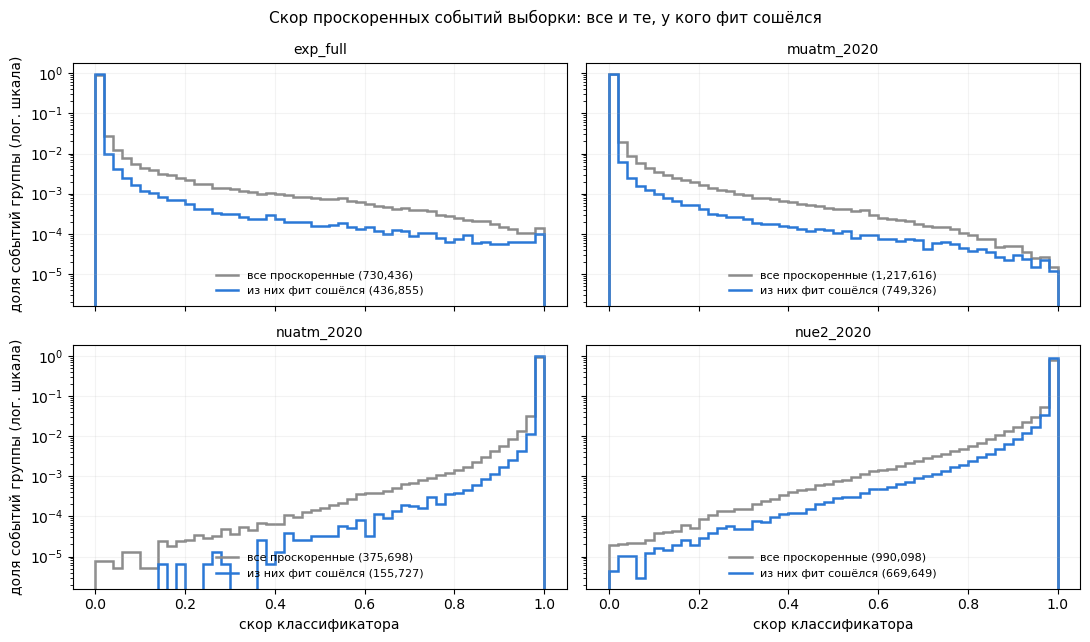

In [9]:
EDGES = np.linspace(0, 1, 51)
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True, sharey=True)
for axis, domain in zip(axes.ravel(), ORDER):
    block = hist[hist.data_class == domain]
    for label, part, colour in (("все проскоренные", block, "#8c8c8c"),
                                ("из них фит сошёлся", block[block.сошёлся],
                                 "#2a78d6")):
        counts = np.zeros(len(EDGES) - 1)
        np.add.at(counts, part.bin.to_numpy(), part.событий.to_numpy())
        axis.stairs(counts / counts.sum(), EDGES, color=colour, lw=1.8,
                    label=f"{label} ({int(counts.sum()):,})")
    axis.set_title(domain, fontsize=10)
    axis.set_yscale("log")
    axis.legend(fontsize=8, frameon=False, loc="lower center")
    axis.grid(alpha=0.15)
for axis in axes[:, 0]:
    axis.set_ylabel("доля событий группы (лог. шкала)")
for axis in axes[1, :]:
    axis.set_xlabel("скор классификатора")
fig.suptitle("Скор проскоренных событий выборки: все и те, у кого фит сошёлся",
             fontsize=11)
fig.tight_layout()
plt.show()

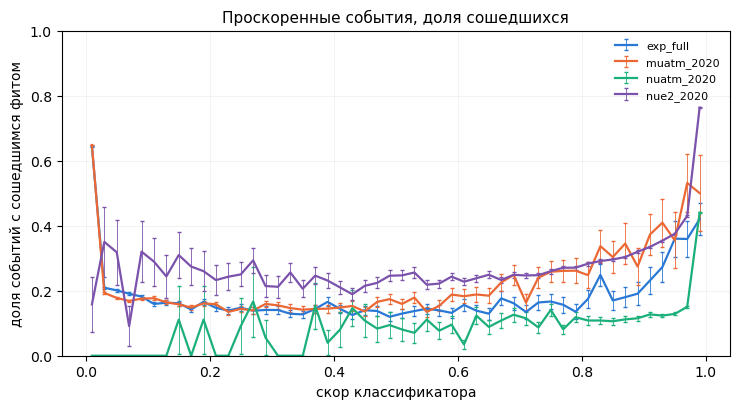

In [10]:
# Доля сошедшихся как функция скора: сдвигает ли фит спектр и насколько.
profile = con.execute("""
    SELECT data_class,
           least(49, greatest(0, floor(score * 50)::INT)) AS bin,
           count(*) AS событий,
           count(*) FILTER (status = 'ok') AS сошлось
    FROM events WHERE score IS NOT NULL GROUP BY 1, 2 ORDER BY 1, 2
""").df()
profile["доля"] = profile.сошлось / profile.событий
profile["ошибка"] = np.sqrt(profile.доля * (1 - profile.доля) / profile.событий)

fig, axis = plt.subplots(figsize=(7.5, 4.2))
for domain, colour in zip(ORDER, ("#2a78d6", "#eb6834", "#1baf7a", "#7b52ab")):
    block = profile[profile.data_class == domain].sort_values("bin")
    axis.errorbar((block.bin + 0.5) / 50, block.доля, yerr=block.ошибка,
                  color=colour, lw=1.6, capsize=1.5, elinewidth=0.6,
                  label=domain)
axis.set(xlabel="скор классификатора", ylabel="доля событий с сошедшимся фитом",
         ylim=(0, 1))
axis.grid(alpha=0.15)
axis.legend(frameon=False, fontsize=8)
axis.set_title("Проскоренные события, доля сошедшихся", fontsize=11)
fig.tight_layout()
plt.show()

## 3. Почему фит не сошёлся

Справочно: состав несшедшихся по статусам — он объясняет, чего в выборке больше.
`no_clique` — не собралась причинная клика, то есть событие слишком бедное;
остальные — отсечения триггеров BARS.

In [11]:
statuses = con.execute("""
    SELECT data_class, status, count(*) AS событий,
           round(100.0 * count(*) / sum(count(*)) OVER (PARTITION BY data_class), 1)
               AS процент
    FROM events GROUP BY 1, 2 ORDER BY data_class, событий DESC
""").df()
statuses

,data_class,status,событий,процент
0,exp_full,no_clique,29115283,97.1
1,exp_full,ok,517749,1.7
2,exp_full,no_offline_trigger,282647,0.9
3,exp_full,no_local_trigger,81081,0.3
4,exp_full,no_global_trigger,3160,0.0
5,muatm_2020,no_clique,7716466,77.2
6,muatm_2020,ok,1616064,16.2
7,muatm_2020,no_offline_trigger,596716,6.0
8,muatm_2020,no_local_trigger,57272,0.6
9,muatm_2020,no_global_trigger,15082,0.2
